# Lesson 1b: Finding cancer dependencies with DepMap

**Goal:** the *data-driven* side of computational cancer biology: finding genes that a specific
cancer type depends on.

### What DepMap is
The [Cancer Dependency Map](https://depmap.org) knocked out almost every gene, one at a time, in
over 1,000 cancer cell lines using CRISPR, and measured whether the cells survived.

- The result is a big table: **cell lines × genes**, each value a **gene effect score**.
- **0** means knocking out the gene does nothing. **-1** is roughly the effect of knocking out a gene every cell needs.
- A gene is a **selective dependency** if *some* cancers need it (very negative) and others don't. Those are drug-target candidates.

Our question: **which genes do leukemia cell lines depend on much more than other cancers?**

### Data
- **Real data (recommended):** download `CRISPRGeneEffect.csv` and `Model.csv` from the
  [DepMap downloads page](https://depmap.org/portal/data_page/?tab=allData) (latest public release)
  and put them in `../data/`, or in Colab upload them with the folder icon on the left. See `../data/README.md`.
- **No download yet?** The notebook falls back to a small **simulated** dataset with the same shape,
  with a few planted leukemia dependencies, so you can learn the workflow. The results then are made up,
  and the notebook says so clearly.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

plt.rcParams["figure.figsize"] = (8, 4.5)
# looks in ../data (local repo), ./data, or the current folder (e.g. files uploaded to Colab)
DATA = next((p for p in [Path("../data"), Path("data"), Path(".")] if (p / "Model.csv").exists()),
            Path("../data"))

In [2]:
effect_path, model_path = DATA / "CRISPRGeneEffect.csv", DATA / "Model.csv"

if effect_path.exists() and model_path.exists():
    SIMULATED = False
    effect = pd.read_csv(effect_path, index_col=0)
    # columns look like "MYB (4602)": keep just the gene symbol
    effect.columns = [c.split(" (")[0] for c in effect.columns]
    models = pd.read_csv(model_path).set_index("ModelID")
    disease = models.loc[models.index.intersection(effect.index), "OncotreePrimaryDisease"]
    is_leuk = disease.str.contains("Leukemia", case=False, na=False)
    effect = effect.loc[disease.index]
else:
    SIMULATED = True
    rng = np.random.default_rng(0)
    n_lines, n_genes = 600, 2000
    genes = [f"GENE{i:04d}" for i in range(n_genes)]
    planted = ["MYB", "SPI1", "CBFB", "LMO2", "MEF2C"]          # leukemia-selective (planted)
    common = ["RPL3", "POLR2A", "PSMA1", "SF3B1", "CDK1"]        # needed by every cell (planted)
    genes[:10] = planted + common
    effect = pd.DataFrame(rng.normal(0, 0.15, (n_lines, n_genes)),
                          index=[f"ACH-{i:06d}" for i in range(n_lines)], columns=genes)
    is_leuk = pd.Series(rng.random(n_lines) < 0.08, index=effect.index)
    for g in planted:
        effect.loc[is_leuk, g] -= rng.normal(0.9, 0.2, is_leuk.sum())
    for g in common:
        effect[g] -= rng.normal(1.1, 0.15, n_lines)

print("SIMULATED DATA (results are made up)" if SIMULATED else "Real DepMap data loaded")
print(f"{effect.shape[0]} cell lines x {effect.shape[1]} genes; {is_leuk.sum()} leukemia lines")
effect.iloc[:5, :6]

Real DepMap data loaded
1208 cell lines x 18531 genes; 54 leukemia lines


,A1BG,A1CF,A2M,A2ML1,A3GALT2,A4GALT
ACH-000001,-0.051662,0.082541,0.002830,-0.112791,0.006381,0.253815
ACH-000004,0.089047,-0.031396,-0.145920,-0.027774,-0.008550,-0.116939
ACH-000005,-0.060334,0.092245,0.139777,0.133384,-0.198775,-0.244170
ACH-000007,0.016785,-0.054811,0.026886,0.136228,0.055993,0.009899
ACH-000009,0.075391,-0.088771,0.046320,0.078070,0.127067,-0.089509


## 1. Look before you analyse

First, the distribution of all gene effects. Most genes do nothing when knocked out (a big peak at 0),
and a small tail of essential genes sits near -1.

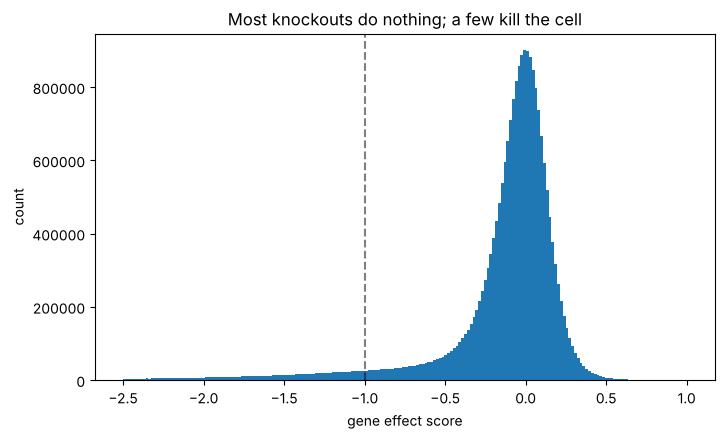

In [3]:
plt.hist(effect.values.ravel(), bins=200, range=(-2.5, 1))
plt.axvline(-1, color="k", ls="--", alpha=0.5)
plt.xlabel("gene effect score"); plt.ylabel("count")
plt.title("Most knockouts do nothing; a few kill the cell")
plt.show()

## 2. Compare leukemia vs. everything else, gene by gene

For each gene we compute:
- **difference in mean effect** (leukemia minus others): more negative means leukemia needs it more
- a **t-test p-value**: is the difference bigger than noise?

Then we correct for testing thousands of genes at once (Benjamini-Hochberg false discovery rate).
Without this step, testing thousands of genes would produce many false positives by chance alone.

In [4]:
data = effect.dropna(axis=1, thresh=int(0.9 * len(effect)))
leuk, rest = data[is_leuk], data[~is_leuk]

diff = leuk.mean() - rest.mean()
t_stat, p = stats.ttest_ind(leuk, rest, nan_policy="omit")
res = pd.DataFrame({"diff": diff, "p": p, "mean_leuk": leuk.mean(), "mean_rest": rest.mean()})

# Benjamini-Hochberg FDR
order = res["p"].sort_values(ascending=False).index
ranked = res["p"].rank(method="first")
res["q"] = (res["p"] * len(res) / ranked)[order].cummin().clip(upper=1)

top = res[(res["q"] < 0.01)].sort_values("diff").head(15)
top

,diff,p,mean_leuk,mean_rest,q
MYB,-1.217982,8.472011e-142,-1.547519,-0.329536,1.493616e-137
CBFB,-1.119416,3.033055e-65,-1.344620,-0.225203,1.782425e-61
CDK6,-0.774789,6.795476e-24,-1.372482,-0.597693,3.864653e-21
ADSL,-0.724024,3.458677e-16,-1.764148,-1.040124,8.588237e-14
RUNX1,-0.722189,5.655892e-82,-0.702442,0.019747,4.985669e-78
UMPS,-0.717644,5.979926e-23,-1.317177,-0.599533,3.100767e-20
CCND3,-0.715074,1.062718e-47,-1.030974,-0.315899,3.747143e-44
NAMPT,-0.688420,5.374433e-28,-1.154104,-0.465684,5.263959e-25
SDHB,-0.668162,1.058968e-24,-1.167768,-0.499607,6.223199e-22
DNM2,-0.650889,3.435778e-18,-1.809833,-1.158944,1.121718e-15


## 3. Volcano plot

The classic picture: effect size on x, significance on y. Selective leukemia dependencies sit in
the **top left**. Genes that every cell needs (like ribosome genes) don't show up there, because
leukemia and other cancers need them equally.

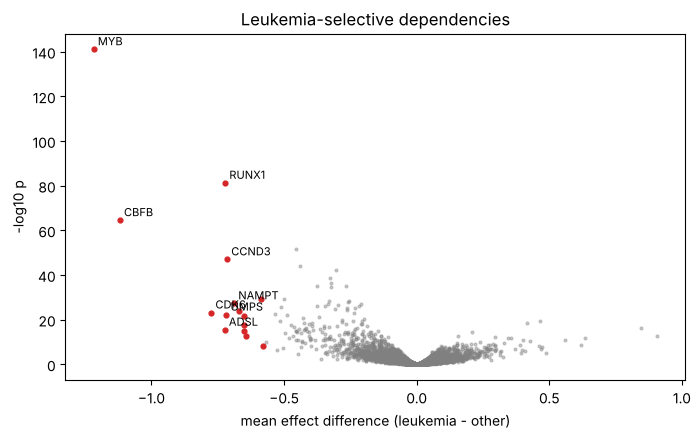

In [5]:
x, y = res["diff"], -np.log10(res["p"].clip(lower=1e-300))
plt.scatter(x, y, s=4, alpha=0.4, color="grey")
hits = res.index.isin(top.index)
plt.scatter(x[hits], y[hits], s=12, color="tab:red")
for g in top.index[:8]:
    plt.annotate(g, (x[g], y[g]), fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.xlabel("mean effect difference (leukemia - other)"); plt.ylabel("-log10 p")
plt.title("Leukemia-selective dependencies" + (" (SIMULATED)" if SIMULATED else ""))
plt.show()

## 4. Look at one gene closely

Statistics summarise; a strip plot shows what is actually going on in each cell line.

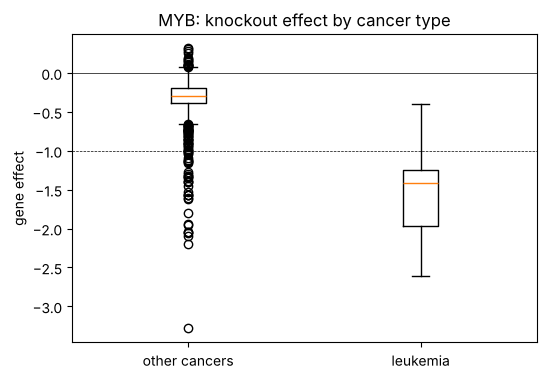

In [6]:
gene = top.index[0]
plt.figure(figsize=(6, 4))
plt.boxplot([rest[gene].dropna(), leuk[gene].dropna()], tick_labels=["other cancers", "leukemia"])
plt.axhline(0, color="k", lw=0.5); plt.axhline(-1, color="k", ls="--", lw=0.5)
plt.ylabel("gene effect"); plt.title(f"{gene}: knockout effect by cancer type")
plt.show()

## Recap and reflection

- You just did the computational core of a real target-discovery analysis: compare groups, test thousands of genes, correct for multiple testing, inspect the hits.
- The biology starts *after* this: **why** does leukemia need this gene? Is it druggable? Is it needed in healthy blood cells too (toxicity)? Answering that means placing the hits in their biological context: pathways, lineage programmes, the immune system.

**Your turn:**
1. With real data: change `"Leukemia"` to another disease (e.g. `"Melanoma"`) and see what comes up.
2. Look up the top hit on depmap.org. Is it a known drug target?

3. Split leukemia into AML and ALL (using `OncotreePrimaryDisease`). Do they share dependencies?